Tutorial: large rotations with the co-rotational kinematics
===

Date: 30 of October 2026

Author: Saullo G. P. Castro

The elements of pyfe3d use either their own von Kármán strains, valid for
small strains and moderate rotations, or, through
`pyfe3d.corotational.CorotationalModel`, the element-independent
co-rotational (EICR) formulation, valid for large displacements and large
rotations with small strains. This notebook compares the three non-linear
kinematics of `CorotationalModel.add()` on three benchmarks of Sze, Liu and
Lo [1]:

| `kinematics` | strains of the element | range of validity |
|---|---|---|
| `'von_karman'` | von Kármán strains in the frame of the undeformed element | small strains, moderate rotations |
| `'corotational'` | linear strains in the co-rotational (CR) frame of the element | small strains, large rotations |
| `'corotational_von_karman'` | von Kármán strains in the CR frame | small strains, large rotations |

In the CR frame the von Kármán terms of the shells (`Quad4R` here) and of
`BeamLR` vanish, and `'corotational_von_karman'` gives the results of
`'corotational'` for them, to round-off; it changes the results of `BeamC`
only, whose von Kármán axial strain is averaged over the element, see the
Notes of `pyfe3d.corotational.CorotationalBeam` and Crisfield [4], Section
17.1.5, Eqs. (17.56a-b).

The cases, with the figures and tables of [1] that give their data and
reference values:

1. Section 3.1, Fig. 2a, Table 2a (p. 1556): cantilever under an end shear
   force, `BeamC` and `Quad4R`, Newton-Raphson;
2. Section 3.2, Fig. 3a, Table 3a (p. 1557): cantilever rolled up into a
   full circle by an end moment, `BeamC` and `Quad4R`, against the exact
   circle, Newton-Raphson;
3. Section 3.8, Fig. 9a, Table 9a (pp. 1564-1565): hinged cylindrical roof,
   12.7 thick, under a central point load, `Quad4R`, Crisfield's
   arc-length method.

The models and the reference values are imported from
`tests/test_corotational_benchmarks.py` and
`tests/test_nonlinear_benchmarks_sze2004.py`, which run the same checks as
tests, with the same tolerances; the convergence of the meshes used here is
documented in the docstrings of those tests. The von Kármán kinematics of
the elements alone, assembled without `CorotationalModel`, are compared
with the same benchmarks in the notebook *Geometrically non-linear
benchmarks*. The cells below run in less than half a minute.

References
---

[1] Sze, K. Y., Liu, X. H. and Lo, S. H., Popular benchmark problems for
geometric nonlinear analysis of shells, *Finite Elements in Analysis and
Design*, 40(11), 1551-1569, 2004,
[doi:10.1016/j.finel.2003.11.001](https://doi.org/10.1016/j.finel.2003.11.001).

[2] Felippa, C. A. and Haugen, B., A unified formulation of small-strain
corotational finite elements: I. Theory, *Computer Methods in Applied
Mechanics and Engineering*, 194(21-24), 2285-2335, 2005,
[doi:10.1016/j.cma.2004.07.035](https://doi.org/10.1016/j.cma.2004.07.035).

[3] Nour-Omid, B. and Rankin, C. C., Finite rotation analysis and
consistent linearization using projectors, *Computer Methods in Applied
Mechanics and Engineering*, 93(3), 353-384, 1991,
[doi:10.1016/0045-7825(91)90248-5](https://doi.org/10.1016/0045-7825(91)90248-5).

[4] Crisfield, M. A., *Non-linear Finite Element Analysis of Solids and
Structures, Volume 2: Advanced Topics*, John Wiley & Sons, Chichester,
1997.

[5] MacNeal, R. H. and Harder, R. L., A proposed standard set of problems
to test finite element accuracy, *Finite Elements in Analysis and Design*,
1(1), 3-20, 1985,
[doi:10.1016/0168-874X(85)90003-4](https://doi.org/10.1016/0168-874X(85)90003-4).

Two settings of the co-rotational models
---

**Rotations below one revolution.** The rotational degrees-of-freedom of
the nodes of co-rotational elements are total rotation vectors
$\boldsymbol{\psi}_a$, the nodal rotation matrix being
$\boldsymbol{R}_a = \exp(\mathrm{Spin}(\boldsymbol{\psi}_a))$; no state is
kept between the evaluations, and the solvers of `pyfe3d.solver` add the
rotation vectors like the translations. The map from the variation of
$\boldsymbol{\psi}$ to the spin, $\boldsymbol{\Lambda}(\boldsymbol{\psi})$
(`pyfe3d.corotational.Lambda`), is singular at
$|\boldsymbol{\psi}| = 2 k \pi$, $k \ge 1$: each nodal rotation must stay
below one full revolution, $|\boldsymbol{\psi}_a| < 2 \pi$. The cantilever
of case 2 reaches this limit, its tip turning by $2 \pi$ at the last load
level, and cannot be continued beyond it.

**Convergence criterion.** The co-rotational kinematics take the nodal
positions relative to the centroid of each element, so that the default
convergence criterion of `pyfe3d.solver` suffices, without `absTOL`.

In [1]:
import os
import sys
import time
sys.path.insert(0, os.path.join('..', '..', 'tests'))

import numpy as np
import matplotlib.pyplot as plt

import pyfe3d
from pyfe3d import DOF
from test_nonlinear_benchmarks_sze2004 import (CANTILEVER, TABLE_3A_EXACT,
    TABLE_9A, elastica_tip, von_karman_tip, run_hinged_roof,
    compare_with_table_9a, limit_points)
from test_corotational_benchmarks import (CANTILEVER_SHEAR, TABLE_2A,
    TABLE_3A_S4R, analysis, at_levels, cantilever,
    tip_deflections, elastica_end_force, polygon_tip,
    run_cantilever_end_shear, run_corotational_roof)

print('pyfe3d', pyfe3d.__version__, 'from', os.path.dirname(pyfe3d.__file__))
KINEMATICS = ['von_karman', 'corotational', 'corotational_von_karman']
STYLE = {'von_karman': 'C0--', 'corotational': 'C1-',
         'corotational_von_karman': 'C2:'}
T_START = time.time()

pyfe3d 0.12.0 from C:\Users\saullogiovanip\repos\pyfe3d\pyfe3d


1. Cantilever under an end shear force (Section 3.1)
===

Fig. 2a of [1]: length $L = 10$, width $b = 1$, thickness $h = 0.1$,
$E = 1.2 \times 10^6$, $\nu = 0$, clamped at $X = 0$, under the end force
$P_{max} = 4 E I/L^2 = 4$ along $+Z$, of fixed direction. Table 2a of [1]
lists $-U$ and $W$ at the tip at 20 load levels, computed with 16x1 S4R
elements; the tip rotates by 64 degrees at $P_{max}$. The reference at
$P_{max}$ is also the inextensible elastica, `elastica_end_force()`,
derived and verified in `tests/test_corotational_benchmarks.py`.

The models: 16 `BeamC` elements, and a strip of 16x1 `Quad4R` elements,
whose bending stiffness per unit width times $b$ is $EI$ for $\nu = 0$,
Newton-Raphson in 20 increments of $0.05 P_{max}$.

**Tolerances**, those of the tests: the co-rotational paths within 1 % of
Table 2a plus 0.0005 for its rounding at the 20 levels, and within 0.2 % of
the elastica at $P_{max}$. Without axial force the von Kármán cantilever
bends as the linear one, $W = P L^3/(3 E I)$, with $u_{,x} = -w_{,x}^2/2$,
which gives $U = -(P/(EI))^2 L^5/15$ (derived in
`test_cantilever_end_shear_von_karman`): the von Kármán paths are checked
against these closed forms, within 0.2 % in $W$ and 0.5 % in $U$.

elastica at P_max: -U 3.2894, W 6.6996; Table 2a: 3.286, 6.698
BeamC   von_karman               0.0 s; at P_max -U 10.6676 (+224.30 %), W 13.3340 (+99.03 %) from the elastica; largest |difference| from Table 2a 7.3816, 6.6360


BeamC   corotational             0.1 s; at P_max -U  3.2889 (  -0.02 %), W  6.7027 ( +0.05 %) from the elastica; largest |difference| from Table 2a 0.0029, 0.0047


BeamC   corotational_von_karman  0.2 s; at P_max -U  3.2895 (  +0.00 %), W  6.7001 ( +0.01 %) from the elastica; largest |difference| from Table 2a 0.0035, 0.0029
Quad4R  von_karman               0.0 s; at P_max -U 10.6417 (+223.51 %), W 13.3211 (+98.83 %) from the elastica; largest |difference| from Table 2a 7.3557, 6.6231


Quad4R  corotational             0.2 s; at P_max -U  3.2862 (  -0.10 %), W  6.6984 ( -0.02 %) from the elastica; largest |difference| from Table 2a 0.0005, 0.0006


Quad4R  corotational_von_karman  0.5 s; at P_max -U  3.2862 (  -0.10 %), W  6.6984 ( -0.02 %) from the elastica; largest |difference| from Table 2a 0.0005, 0.0006
BeamC von_karman: W over Table 2a 1.0056 at 0.05 P_max, 1.0186 at 0.10 P_max, 1.991 at P_max
Quad4R von_karman: W over Table 2a 1.0046 at 0.05 P_max, 1.0177 at 0.10 P_max, 1.989 at P_max


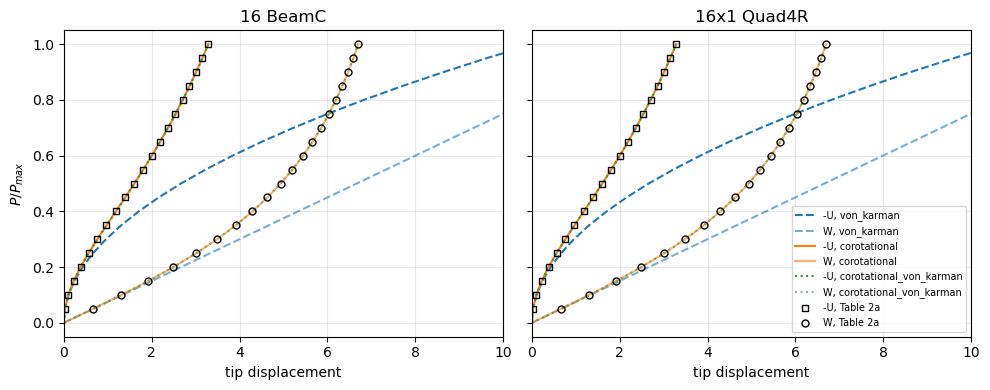

In [2]:
L, b, h, E, Pmax = (CANTILEVER_SHEAR[k] for k in ('L', 'b', 'h', 'E', 'Pmax'))
EI = E*b*h**3/12
Ue, We = elastica_end_force(4.)
print('elastica at P_max: -U %.4f, W %.4f; Table 2a: %.3f, %.3f'
      % (L*Ue, L*We, TABLE_2A[-1, 1], TABLE_2A[-1, 2]))
shear = {}
for element in ['BeamC', 'Quad4R']:
    for kin in KINEMATICS:
        m, U, W, t = run_cantilever_end_shear(element, 16, kinematics=kin)
        shear[element, kin] = m, U, W
        idx = at_levels(m, TABLE_2A[:, 0])
        print('%-7s %-24s %.1f s; at P_max -U %7.4f (%+7.2f %%), W %7.4f (%+6.2f %%) '
              'from the elastica; largest |difference| from Table 2a %.4f, %.4f'
              % (element, kin, t, U[-1], 100*(U[-1]/(L*Ue) - 1), W[-1],
                 100*(W[-1]/(L*We) - 1), np.abs(U[idx] - TABLE_2A[:, 1]).max(),
                 np.abs(W[idx] - TABLE_2A[:, 2]).max()))
        assert np.isclose(m[-1], 1.)
        if kin == 'von_karman':
            P = m*Pmax
            np.testing.assert_allclose(W, P*L**3/(3*EI), rtol=2e-3)
            np.testing.assert_allclose(U, (P/EI)**2*L**5/15, rtol=5e-3)
        else:
            np.testing.assert_allclose(U[idx], TABLE_2A[:, 1], rtol=0.01, atol=0.0005)
            np.testing.assert_allclose(W[idx], TABLE_2A[:, 2], rtol=0.01, atol=0.0005)
            assert abs(U[-1]/(L*Ue) - 1) <= 0.002
            assert abs(W[-1]/(L*We) - 1) <= 0.002
for element in ['BeamC', 'Quad4R']:
    m, U, W = shear[element, 'von_karman']
    idx = at_levels(m, TABLE_2A[:, 0])
    print('%s von_karman: W over Table 2a %.4f at 0.05 P_max, %.4f at 0.10 P_max, %.3f at P_max'
          % (element, W[idx[0]]/TABLE_2A[0, 2], W[idx[1]]/TABLE_2A[1, 2], W[-1]/TABLE_2A[-1, 2]))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, element in zip(axes, ['BeamC', 'Quad4R']):
    for kin in KINEMATICS:
        m, U, W = shear[element, kin]
        ax.plot(np.r_[0, U], np.r_[0, m], STYLE[kin], lw=1.5, label='-U, %s' % kin)
        ax.plot(np.r_[0, W], np.r_[0, m], STYLE[kin], lw=1.5, alpha=0.6, label='W, %s' % kin)
    ax.plot(TABLE_2A[:, 1], TABLE_2A[:, 0], 'ks', mfc='none', ms=5, label='-U, Table 2a')
    ax.plot(TABLE_2A[:, 2], TABLE_2A[:, 0], 'ko', mfc='none', ms=5, label='W, Table 2a')
    ax.set_title('16 %s' % element if element == 'BeamC' else '16x1 Quad4R')
    ax.set_xlim(0, 10)
    ax.set_xlabel('tip displacement')
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel('$P/P_{max}$')
axes[1].legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.show()

The two co-rotational kinematics follow Table 2a at all 20 levels with
both elements, within its rounding with `Quad4R`; at $P_{max}$ they are
within 0.1 % of the elastica, whose difference from Table 2a is of the same
order. The von Kármán path leaves Table 2a at once: its deflection is
already 1.8 % too large at $0.1 P_{max}$, a tip rotation of 0.2 rad, and
it ends at twice the deflection of Table 2a, its tip moving back by
$-U = 10.7$, more than the length of the cantilever. These are the closed
forms above, the expected result of the von Kármán strains, not an error of
the elements.

With `Quad4R`, `'corotational_von_karman'` gives the path of
`'corotational'`, since the von Kármán terms of the shell vanish in its CR
frame. With `BeamC` it changes the path slightly, and moves it towards the
elastica: the element-averaged von Kármán axial strain adds in the CR frame
the local higher-order terms of [4], Eq. (17.56a), which make coarse meshes
more accurate, see the table of
`test_cantilever_end_shear_corotational_von_karman` (with 4 elements,
-0.24 % and +0.68 % from the elastica with `'corotational'`, -0.013 % and
-0.010 % with `'corotational_von_karman'`).

2. Cantilever rolled up into a circle (Section 3.2)
===

Fig. 3a of [1]: $L = 12$, $b = 1$, $h = 0.1$, $E = 1.2 \times 10^6$,
$\nu = 0$, clamped at $X = 0$, under the end moment
$M_{max} = 2 \pi E I/L$ about $-Y$, which bends the cantilever into a full
circle of radius $L/(2\pi)$, the tip returning to the root after turning by
$2 \pi$. The exact tip deflections, $U/L = \sin\varphi/\varphi - 1$ and
$W/L = (1 - \cos\varphi)/\varphi$ with $\varphi = M L/(EI)$, are listed in
Table 3a of [1] (`elastica_tip()`, checked against Table 3a in
`tests/test_nonlinear_benchmarks_sze2004.py`).

The models: 16 `BeamC` elements and 16x1 `Quad4R`, Newton-Raphson in
increments of $0.05 M_{max}$ (`BeamC`) and $0.025 M_{max}$ (`Quad4R`;
with 0.05, Newton-Raphson cuts back three increments and misses the levels
of Table 3a). The moment is applied with `add_moment()` for the
co-rotational models, conjugate to the rotation vector, which is here the
moment about the fixed axis $-Y$, since $\boldsymbol{\Lambda}^T
\boldsymbol{n} = \boldsymbol{n}$ for $\boldsymbol{\psi} \parallel
\boldsymbol{n}$; for the von Kármán model it is the constant nodal moment
of `fext`. The out-of-plane rotations $\psi_X$ and $\psi_Z$ are restrained
at all the nodes, exact for this plane problem.

With 16 elements of equal length and no axial or shear force, the discrete
solution is the polygon of 16 equal chords inscribed in the exact circle
(`polygon_tip()`, derived in `tests/test_corotational_benchmarks.py`),
which differs from the exact circle by at most $0.0011 L$; the S4R columns
of Table 3a, also 16x1, lie on that polygon within 0.0005.

**Tolerances**, those of the tests: `'corotational'` on the polygon within
$10^{-7} L$ and within 0.001 of the S4R columns of Table 3a; the von Kármán
paths on the von Kármán solution, $W/L = \varphi/2$ and
$U/L = -\varphi^2/6$ (`von_karman_tip()`), to $10^{-6}$ in $W$ and 0.2 % in
$U$, the tolerances of `test_cantilever_end_moment_quad4r`.

In [3]:
def run_end_moment(element, kinematics, inc, num_elements=16):
    L, b, h, E = (CANTILEVER[k] for k in ('L', 'b', 'h', 'E'))
    Mmax = 2*np.pi*E*b*h**3/12/L
    model, bu, tip = cantilever(element, num_elements, L, b, h, E,
                                kinematics=kinematics)
    for n in tip:
        if kinematics == 'von_karman':
            model.fext[DOF*n + 4] = -Mmax/len(tip)
        else:
            model.add_moment(n, [0., -Mmax/len(tip), 0.])
    # NOTE plane problem: out-of-plane rotations restrained
    bu[3::DOF] = False
    bu[5::DOF] = False
    m, cs, t = analysis(model, bu, inc)
    U, W = tip_deflections(cs, tip)
    return dict(m=m, U=U/L, W=W/L, cs=cs, model=model, tip=tip, t=t)


L = CANTILEVER['L']
mt = TABLE_3A_EXACT[:, 0]
U_ex, W_ex = elastica_tip(mt)
U_pol, W_pol = polygon_tip(mt, 16)
U_vk, W_vk = von_karman_tip(mt)
print('polygon of 16 chords against the exact circle: largest |difference| %.5f L, %.5f L'
      % (np.abs(U_pol - U_ex).max(), np.abs(W_pol - W_ex).max()))
moment = {}
for element, inc in [('BeamC', 0.05), ('Quad4R', 0.025)]:
    for kin in KINEMATICS:
        r = run_end_moment(element, kin, inc)
        moment[element, kin] = r
        idx = at_levels(r['m'], mt)
        U, W = r['U'][idx], r['W'][idx]
        rot = np.mean([r['cs'][-1][DOF*n + 4] for n in r['tip']])
        assert np.isclose(r['m'][-1], 1.)
        print('%-7s %-24s %.1f s; at M_max -U/L %.5f, W/L %.5f, tip rotation %.6f pi'
              % (element, kin, r['t'], r['U'][-1], r['W'][-1], rot/np.pi))
        if kin == 'von_karman':
            print('    largest |W/L - von Kármán| %.1e, |U/U_vk - 1| %.1e'
                  % (np.abs(W - W_vk).max(), np.abs(U/U_vk - 1).max()))
            np.testing.assert_allclose(W, W_vk, rtol=1e-6)
            np.testing.assert_allclose(U, U_vk, rtol=2e-3)
        else:
            print('    largest |difference| from the polygon %.1e, %.1e; from the exact '
                  'circle %.1e, %.1e; from the S4R columns of Table 3a %.4f, %.4f'
                  % (np.abs(U - U_pol).max(), np.abs(W - W_pol).max(),
                     np.abs(U - U_ex).max(), np.abs(W - W_ex).max(),
                     np.abs(L*U - TABLE_3A_S4R[:, 1]).max(),
                     np.abs(L*W - TABLE_3A_S4R[:, 2]).max()))
            assert np.isclose(rot, -2*np.pi, rtol=1e-8)
            if element == 'BeamC' and kin == 'corotational_von_karman':
                # NOTE on the exact circle, see the text below
                np.testing.assert_allclose(U, U_ex, rtol=0, atol=2e-6)
                np.testing.assert_allclose(W, W_ex, rtol=0, atol=2e-6)
            else:
                np.testing.assert_allclose(U, U_pol, rtol=0, atol=1e-7)
                np.testing.assert_allclose(W, W_pol, rtol=0, atol=1e-7)
                np.testing.assert_allclose(L*U, TABLE_3A_S4R[:, 1], rtol=0, atol=0.001)
                np.testing.assert_allclose(L*W, TABLE_3A_S4R[:, 2], rtol=0, atol=0.001)

polygon of 16 chords against the exact circle: largest |difference| 0.00078 L, 0.00111 L
BeamC   von_karman               0.0 s; at M_max -U/L 6.57974, W/L 3.14159, tip rotation -2.000000 pi
    largest |W/L - von Kármán| 7.3e-12, |U/U_vk - 1| 4.5e-12


BeamC   corotational             0.2 s; at M_max -U/L 1.00000, W/L -0.00000, tip rotation -2.000000 pi
    largest |difference| from the polygon 7.8e-16, 9.7e-16; from the exact circle 7.8e-04, 1.1e-03; from the S4R columns of Table 3a 0.0005, 0.0005


BeamC   corotational_von_karman  0.4 s; at M_max -U/L 1.00000, W/L 0.00000, tip rotation -2.000000 pi
    largest |difference| from the polygon 7.8e-04, 1.1e-03; from the exact circle 9.8e-07, 8.9e-07; from the S4R columns of Table 3a 0.0095, 0.0137
Quad4R  von_karman               0.1 s; at M_max -U/L 6.57331, W/L 3.14159, tip rotation -2.000000 pi
    largest |W/L - von Kármán| 6.0e-10, |U/U_vk - 1| 9.8e-04


Quad4R  corotational             0.6 s; at M_max -U/L 1.00000, W/L -0.00000, tip rotation -2.000000 pi
    largest |difference| from the polygon 3.3e-15, 4.2e-15; from the exact circle 7.8e-04, 1.1e-03; from the S4R columns of Table 3a 0.0005, 0.0005


Quad4R  corotational_von_karman  1.1 s; at M_max -U/L 1.00000, W/L -0.00000, tip rotation -2.000000 pi
    largest |difference| from the polygon 3.8e-15, 3.7e-15; from the exact circle 7.8e-04, 1.1e-03; from the S4R columns of Table 3a 0.0005, 0.0005


Both elements with `'corotational'` lie on the polygon of 16 chords to
round-off at the 20 levels, and their tips turn by exactly $2 \pi$ at
$M_{max}$, back at the root: the full circle. The von Kármán models follow
the von Kármán solution, which agrees with the exact one only for small
rotations, and end at $W = \pi L$, $-U = 6.6 L$, far from the root.

`BeamC` with `'corotational_von_karman'` does better than the polygon: its
tip lies on the exact circle within $10^{-6} L$, because the averaged
von Kármán axial strain in the CR frame accounts for the arc of each
element against its chord. Measured separately on 2026-10-30, its largest
distance from the exact tip over the 20 levels is $5 \times 10^{-3} L$,
$2.7 \times 10^{-4} L$ and $1.0 \times 10^{-6} L$ with 2, 4 and 16
elements, decreasing about as $n^{-4}$. With `Quad4R` the two
co-rotational kinematics coincide.

The deformed cantilevers at four levels of Table 3a, without
amplification, with the exact circles:

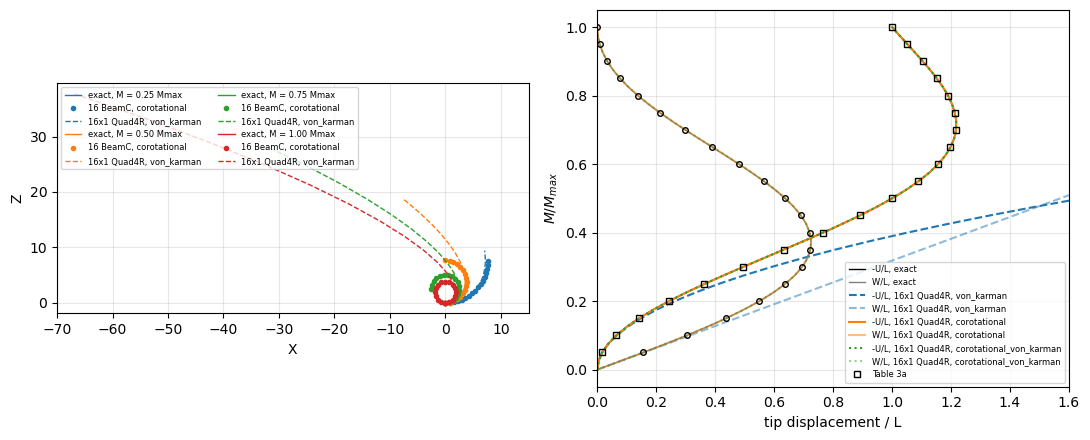

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
s = np.linspace(0, L, 200)
for frac, color in [(0.25, 'C0'), (0.5, 'C1'), (0.75, 'C2'), (1.0, 'C3')]:
    radius = L/(2*np.pi*frac)
    axes[0].plot(radius*np.sin(s/radius), radius*(1 - np.cos(s/radius)), '-',
                 color=color, lw=1, label='exact, M = %.2f Mmax' % frac)
    r = moment['BeamC', 'corotational']
    i = int(np.argmin(np.abs(r['m'] - frac)))
    x = r['model'].x.reshape(-1, 3)
    u = r['cs'][i].reshape(-1, DOF)
    axes[0].plot(x[:, 0] + u[:, 0], x[:, 2] + u[:, 2], 'o', color=color, ms=3,
                 label='16 BeamC, corotational')
    r = moment['Quad4R', 'von_karman']
    i = int(np.argmin(np.abs(r['m'] - frac)))
    x = r['model'].x.reshape(-1, 3)
    u = r['cs'][i].reshape(-1, DOF)
    edge = np.isclose(x[:, 1], 0.)
    axes[0].plot(x[edge, 0] + u[edge, 0], x[edge, 2] + u[edge, 2], '--',
                 color=color, lw=1, label='16x1 Quad4R, von_karman')
axes[0].set_aspect('equal')
axes[0].set_xlim(-70, 15)
axes[0].set_xlabel('X')
axes[0].set_ylabel('Z')
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=6, ncol=2, loc='upper left')
mm = np.linspace(0, 1, 201)
Uc, Wc = elastica_tip(mm)
axes[1].plot(Uc, mm, 'k-', lw=1, label='-U/L, exact')
axes[1].plot(Wc, mm, 'k-', lw=1, alpha=0.5, label='W/L, exact')
for kin in KINEMATICS:
    r = moment['Quad4R', kin]
    axes[1].plot(np.r_[0, r['U']], np.r_[0, r['m']], STYLE[kin], lw=1.5,
                 label='-U/L, 16x1 Quad4R, %s' % kin)
    axes[1].plot(np.r_[0, r['W']], np.r_[0, r['m']], STYLE[kin], lw=1.5,
                 alpha=0.5, label='W/L, 16x1 Quad4R, %s' % kin)
axes[1].plot(TABLE_3A_EXACT[:, 1]/L, mt, 'ks', mfc='none', ms=4, label='Table 3a')
axes[1].plot(TABLE_3A_EXACT[:, 2]/L, mt, 'ko', mfc='none', ms=4)
axes[1].set_xlim(0, 1.6)
axes[1].set_xlabel('tip displacement / L')
axes[1].set_ylabel('$M/M_{max}$')
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=6, loc='lower right')
plt.tight_layout()
plt.show()

3. Hinged cylindrical roof, 12.7 thick (Section 3.8)
===

Fig. 9a of [1]: cylindrical roof of radius $R = 2540$, length $2L$ with
$L = 254$, opening $2\theta$ with $\theta = 0.1$ rad, thickness $h = 12.7$,
$E = 3102.75$, $\nu = 0.3$, straight edges hinged with all the translations
restrained, curved edges free, central point load $P$ with
$P_{max} = 3000$. One quarter is meshed with 8x8 `Quad4R` elements and
their default stabilisation, and the snap-through is traced with
Crisfield's arc-length method up to $1.2 P_{max}$, with increments of
`initialInc = maxInc = 0.05`, for the three kinematics (`hinged_roof()`,
`run_hinged_roof()` and `run_corotational_roof()` of the tests). Table 9a
of [1] lists the path of 16x16 S4R elements.

**Tolerances**, those of the tests, which follow the grades of [5], p. 14:
the upper limit load within 2 % of Table 9a (grade A) and the lower one
within 10 % (grade B), the 8x8 mesh being coarser than that of Table 9a;
`'corotational'` and `'von_karman'` within 0.001 $P_{max}$ of each other up
to the upper limit point, and within 0.03 $P_{max}$ along the whole path;
`'corotational_von_karman'` on the path of `'corotational'` to
$10^{-9} P_{max}$.

von_karman               83 increments, 2.5 s


corotational             82 increments, 3.0 s


corotational_von_karman  82 increments, 6.0 s
von_karman               upper limit 0.74293 (+0.11 %), lower limit 0.17183 (-0.62 %), at -W_C = 29.374: 1.0800
corotational             upper limit 0.74211 (+0.00 %), lower limit 0.17306 (+0.09 %), at -W_C = 29.374: 1.1003
corotational_von_karman  upper limit 0.74211 (+0.00 %), lower limit 0.17306 (+0.09 %), at -W_C = 29.374: 1.1003
Table 9a: upper limit 0.7421, lower limit 0.1729, at -W_C = 29.374: 1.0835
|corotational - von_karman| at the points of Table 9a: 0.0009 up to the upper limit point, 0.0203 along the path
corotational_von_karman - corotational: 6.6e-15 in P/P_max


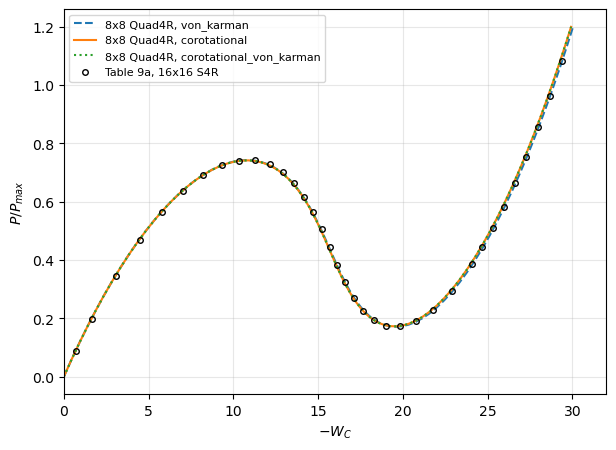

total time of the notebook 16 s


In [5]:
roof = {}
for kin in KINEMATICS:
    t0 = time.time()
    if kin == 'von_karman':
        P, W = run_hinged_roof(n=8)
    else:
        P, W, _ = run_corotational_roof(n=8, kinematics=kin)
    roof[kin] = P, W
    print('%-24s %d increments, %.1f s' % (kin, P.size - 1, time.time() - t0))
(Pu_ref, _), (Pl_ref, _) = limit_points(TABLE_9A[:, 0], TABLE_9A[:, 1], 15.)
calc = {}
for kin, (P, W) in roof.items():
    (Pu, Wu), (Pl, Wl) = limit_points(P, W, 15.)
    calc[kin] = compare_with_table_9a(P, W)
    print('%-24s upper limit %.5f (%+.2f %%), lower limit %.5f (%+.2f %%), at -W_C = 29.374: %.4f'
          % (kin, Pu, 100*(Pu/Pu_ref - 1), Pl, 100*(Pl/Pl_ref - 1), calc[kin][-1]))
    assert abs(Pu/Pu_ref - 1) <= 0.02
    assert abs(Pl/Pl_ref - 1) <= 0.10
print('Table 9a: upper limit %.4f, lower limit %.4f, at -W_C = 29.374: %.4f'
      % (Pu_ref, Pl_ref, TABLE_9A[-1, 0]))
before = TABLE_9A[:, 1] <= 11.3
diff = np.abs(calc['corotational'] - calc['von_karman'])
print('|corotational - von_karman| at the points of Table 9a: %.4f up to the upper '
      'limit point, %.4f along the path' % (diff[before].max(), diff.max()))
assert diff[before].max() <= 0.001
assert diff.max() <= 0.03
P, W = roof['corotational_von_karman']
Pc, Wc = roof['corotational']
assert P.size == Pc.size
print('corotational_von_karman - corotational: %.1e in P/P_max' % np.abs(P - Pc).max())
assert np.abs(P - Pc).max() <= 1e-9

fig, ax = plt.subplots(figsize=(7, 5))
for kin in KINEMATICS:
    ax.plot(roof[kin][1], roof[kin][0], STYLE[kin], lw=1.5, label='8x8 Quad4R, %s' % kin)
ax.plot(TABLE_9A[:, 1], TABLE_9A[:, 0], 'ko', mfc='none', ms=4,
        label='Table 9a, 16x16 S4R')
ax.set_xlabel('$-W_C$')
ax.set_ylabel('$P/P_{max}$')
ax.set_xlim(0, 32)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
plt.show()
print('total time of the notebook %.0f s' % (time.time() - T_START))

The rotations of the roof stay small, and the two kinematics agree within
0.001 $P_{max}$ up to the upper limit point, $-W_C \approx 11$; they then
part, by up to 0.02 $P_{max}$ at the end of Table 9a, $-W_C = 29.4$, where
the deflection is about two thicknesses. On this 8x8 mesh the co-rotational
path is 1.5 % above Table 9a at its last point and the von Kármán one
0.3 % below. Measured in `test_hinged_roof_thick_corotational` with the
16x16 mesh of Table 9a: 0.4 % above and 1.4 % below, i.e. S4R, whose
kinematics are those of finite rotations, follows the co-rotational path
when the meshes are the same. `'corotational_von_karman'` gives the path
of `'corotational'` to round-off, as expected for `Quad4R`.

Summary
---

| case | reference | `'von_karman'` | `'corotational'` | `'corotational_von_karman'` |
|---|---|---|---|---|
| 3.1, end shear, 64 degrees | Table 2a, elastica | linear deflection, twice Table 2a at $P_{max}$ | within the tolerance of Table 2a, 0.1 % of the elastica | `Quad4R`: as `'corotational'`; `BeamC`: closer to the elastica |
| 3.2, end moment, $2 \pi$ | exact circle, Table 3a | never rolls up, $W = \pi L$ at $M_{max}$ | the inscribed polygon to round-off, full circle | `Quad4R`: as `'corotational'`; `BeamC`: the exact circle within $10^{-6} L$ |
| 3.8, roof, snap-through | Table 9a | limit loads grade A and B | limit loads grade A and B, closer to S4R at large deflections | as `'corotational'` |

The slit annular plate (Section 3.3) and the hemispherical shell (Section
3.4) of [1], with large rotations of shells, take about 10 s each with the
meshes of the tests, and are run in `tests/test_corotational_benchmarks.py`
only.